<a href="https://colab.research.google.com/github/But-Vladyslava/Machine-Learning-Uni-/blob/main/%D0%9B%D0%A05_%D0%91%D1%83%D1%82_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
# Імпортуйте необхідні бібліотеки
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
# Завантажте датасет з Kaggle

import kagglehub

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")
print("Шлях до завантаженого датасету:", path)

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Шлях до завантаженого датасету: /kaggle/input/daily-climate-time-series-data-delhi-india


In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані

csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
print("Знайдені CSV файли:", csv_files)

if csv_files:
    file_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(file_path)
    display(df.head())
else:
    print("CSV файлів у директорії не знайдено")

Знайдені CSV файли: ['kaggel_weather_2013_to_2024.csv']


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Опис датасету:
* **Unnamed: 0**: Індексний рядок або службовий номер рядка у таблиці.
* **DATE**: Дата проведення вимірювань (у форматі місяць/день/рік).
* **tempmax**: Максимальна температура за день.
* **tempmin**: Мінімальна температура за день.
* **temp**: Середня температура за день.
* **feelslikemax**: Максимальна температура за відчуттями (з урахуванням вологості та вітру).
* **feelslikemin**: Мінімальна температура за відчуттями.
* **feelslike**: Середня температура за відчуттями.
* **humidity**: Відносна вологість повітря (у відсотках).
* **precip**: Кількість опадів (дощу тощо).
* **precipprob**: Ймовірність випадання опадів.
* **precipcover**: Покриття опадами (відсоток території або часу з опадами).
* **windspeed**: Швидкість вітру.
* **sealevelpressure**: Атмосферний тиск на рівні моря.
* **conditions**: Погодні умови (наприклад, Clear — ясно, Partially cloudy — мінлива хмарність, Rain — дощ).
* **Year**: Рік вимірювання.
* **month**: Місяць вимірювання.
* **dayofweek**: День тижня (порядковий номер).
* **dayofyear**: День року (від 1 до 365/366).
* **year-2000**: Рік мінус 2000 (для зручності розрахунків).

Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

df['DATE'] = pd.to_datetime(df['DATE'])

df = df.sort_values(by='DATE')

if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

df = df.set_index('DATE')
display(df.head())


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [5]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  month                  3557 non-null  

In [6]:
# Перевірте наявність пропущених значень

df.isnull().sum()

,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0


Графік температури

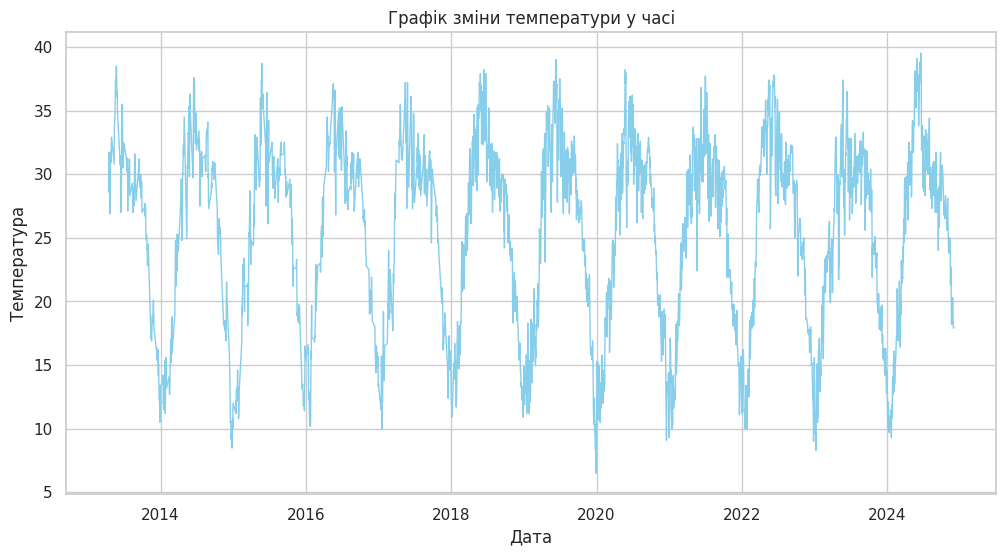

In [7]:
# Побудуйте графік зміни температури у часі

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['temp'], color='skyblue', linewidth=1)
plt.title('Графік зміни температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура')

plt.show()

Ковзне середнє

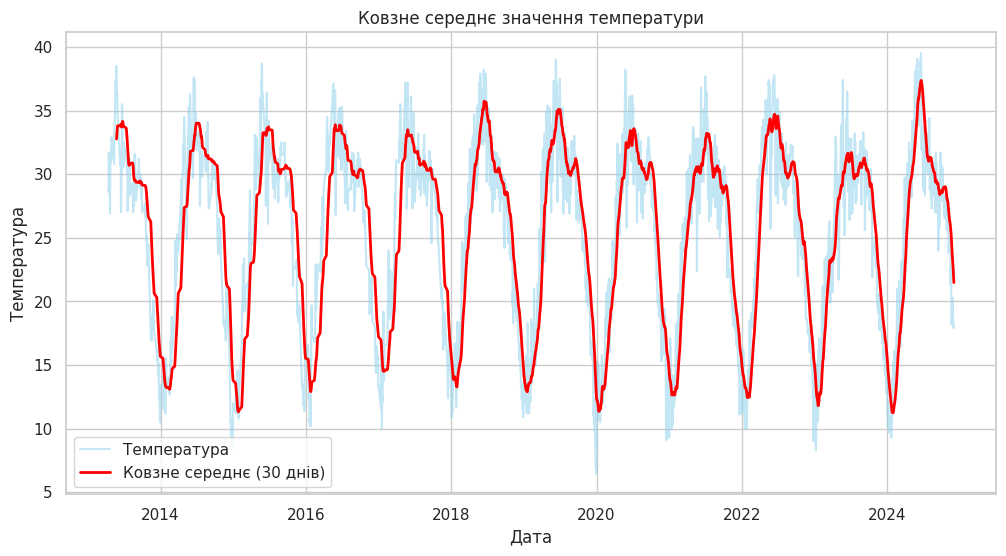

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури

df['temp_rolling_30'] = df['temp'].rolling(window=30).mean()

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['temp'], label='Температура', color='skyblue', alpha=0.5)
plt.plot(df.index, df['temp_rolling_30'], label='Ковзне середнє (30 днів)', color='red', linewidth=2)
plt.title('Ковзне середнє значення температури')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()

plt.show()

Розподіл температури

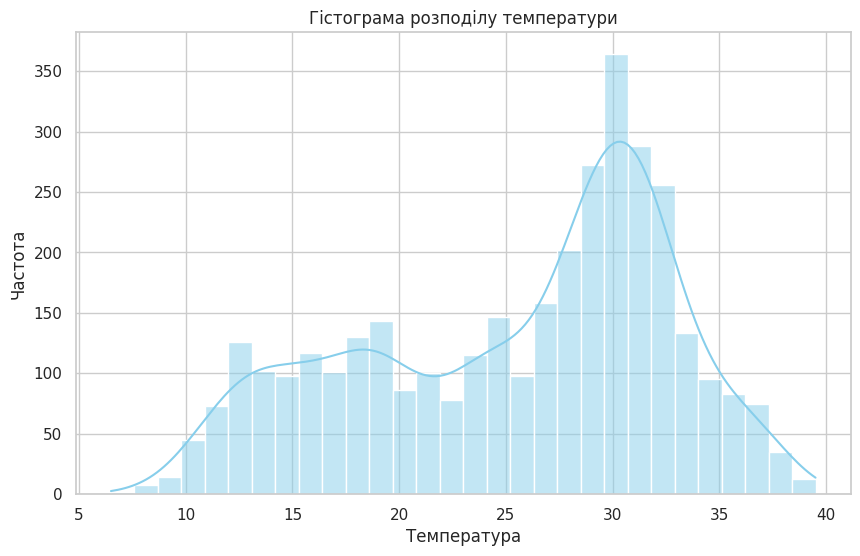

In [9]:
# Побудуйте гістограму розподілу температури

plt.figure(figsize=(10, 6))
sns.histplot(df['temp'], bins=30, kde=True, color='skyblue')
plt.title('Гістограма розподілу температури')
plt.xlabel('Температура')
plt.ylabel('Частота')

plt.show()

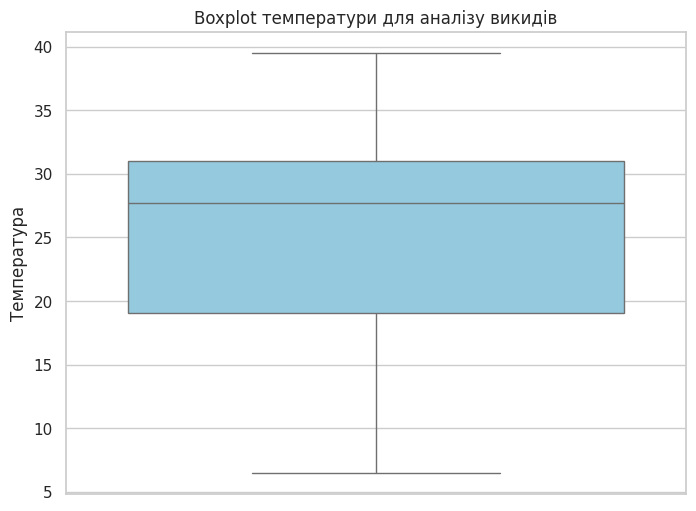

In [10]:
# Побудуйте boxplot температури для аналізу викидів

plt.figure(figsize=(8, 6))
sns.boxplot(y=df['temp'], color='skyblue')
plt.title('Boxplot температури для аналізу викидів')
plt.ylabel('Температура')

plt.show()

Аналіз автокореляції
ACF

PACF

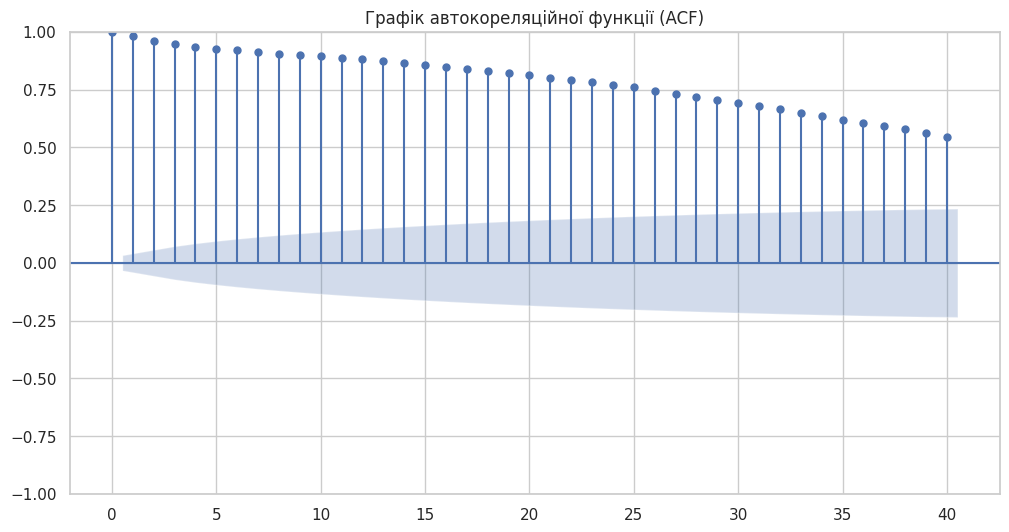

In [11]:
# Побудуйте графік автокореляційної функції (ACF)

from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 6))
plot_acf(df['temp'].dropna(), lags=40, ax=plt.gca())
plt.title('Графік автокореляційної функції (ACF)')

plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

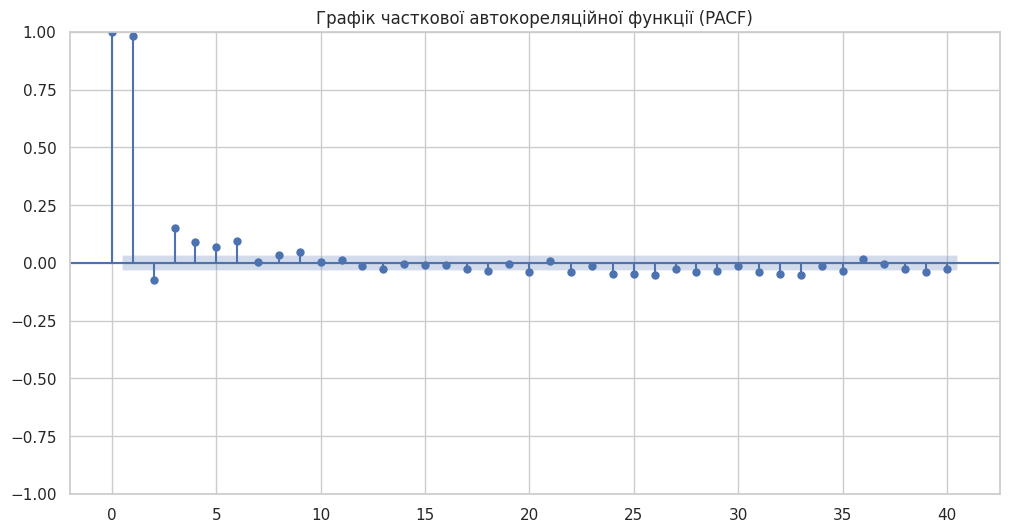

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)

from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 6))
plot_pacf(df['temp'].dropna(), lags=40, ax=plt.gca(), method='ywm')
plt.title('Графік часткової автокореляційної функції (PACF)')

plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку

train_size = int(len(df) * 0.8)
train = df['temp'][:train_size]
test = df['temp'][train_size:]
print(len(train), len(test))

2845 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки

from statsmodels.tsa.arima.model import ARIMA
import numpy as np

# Перетворюємо дані у числовий масив
temp_values = df['temp'].astype(float).values

predictions = list()
n_test = len(test)

# Проходимо по кожному елементу тестової вибірки
for i in range(n_test):
    train_len = len(train) + i
    train_data = temp_values[:train_len]

    # Ініціалізуємо та навчаємо модель
    model = ARIMA(train_data, order=(3, 1, 0))
    model_fit = model.fit()

    # Робимо прогноз і точно витягуємо його як звичайне число (float)
    output = model_fit.forecast()
    yhat = float(output.iloc[0]) if hasattr(output, 'iloc') else float(output[0])

    predictions.append(yhat)

In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі

print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 3556
Model:                 ARIMA(3, 1, 0)   Log Likelihood               -6189.442
Date:                Thu, 05 Nov 2026   AIC                          12386.885
Time:                        12:54:26   BIC                          12411.589
Sample:                             0   HQIC                         12395.694
                               - 3556                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0585      0.014      4.117      0.000       0.031       0.086
ar.L2         -0.1576      0.015    -10.419      0.000      -0.187      -0.128
ar.L3         -0.0977      0.015     -6.422      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

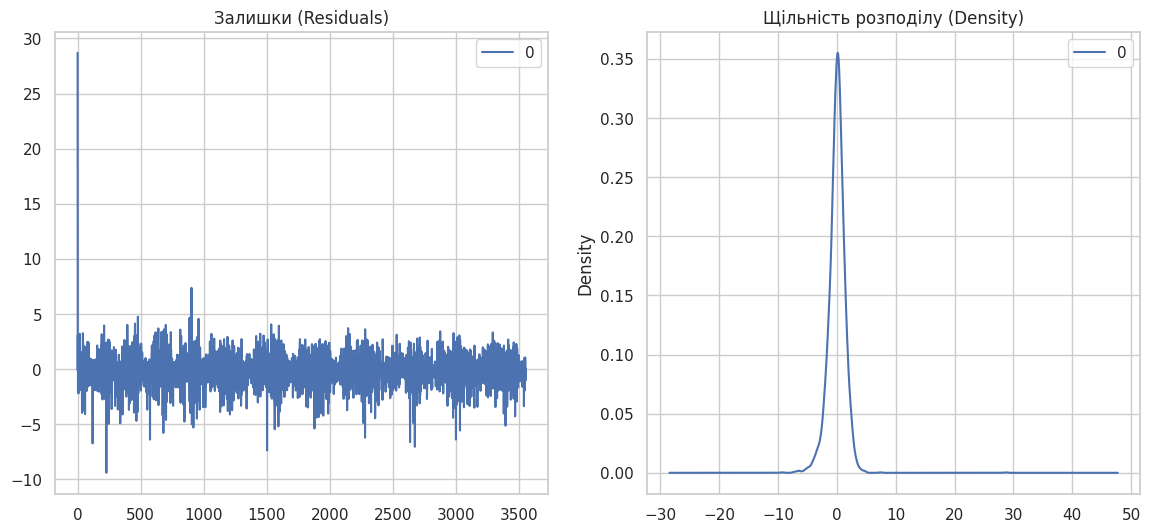

In [16]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки

import pandas as pd
from matplotlib import pyplot

# Збираємо залишки моделі у датафрейм
residuals = pd.DataFrame(model_fit.resid)

# Створюємо полотно з двома графіками поруч
fig, ax = pyplot.subplots(1, 2, figsize=(14, 6))

# Перший графік: залишки в часі (Residuals)
residuals.plot(title="Залишки (Residuals)", ax=ax[0])

# Другий графік: графік щільності розподілу помилок (Density / KDE)
residuals.plot(kind='kde', title='Щільність розподілу (Density)', ax=ax[1])

pyplot.show()


In [17]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA

from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import numpy as np

# Функція для розрахунку MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true, dtype=float), np.array(y_pred, dtype=float)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Перетворюю у масиви однакової довжини
y_pred = np.array(predictions, dtype=float)
y_true = np.array(test, dtype=float)[-len(y_pred):]

# Обчислення метрик
rmse = sqrt(mean_squared_error(y_true, y_pred))
mae = mean_absolute_error(y_true, y_pred)
mape = mean_absolute_percentage_error(y_true, y_pred)

print(f'Test RMSE: {rmse:.3f}')
print(f'Test MAE:  {mae:.3f}')
print(f'Test MAPE: {mape:.3f}%')

Test RMSE: 1.294
Test MAE:  0.986
Test MAPE: 4.285%


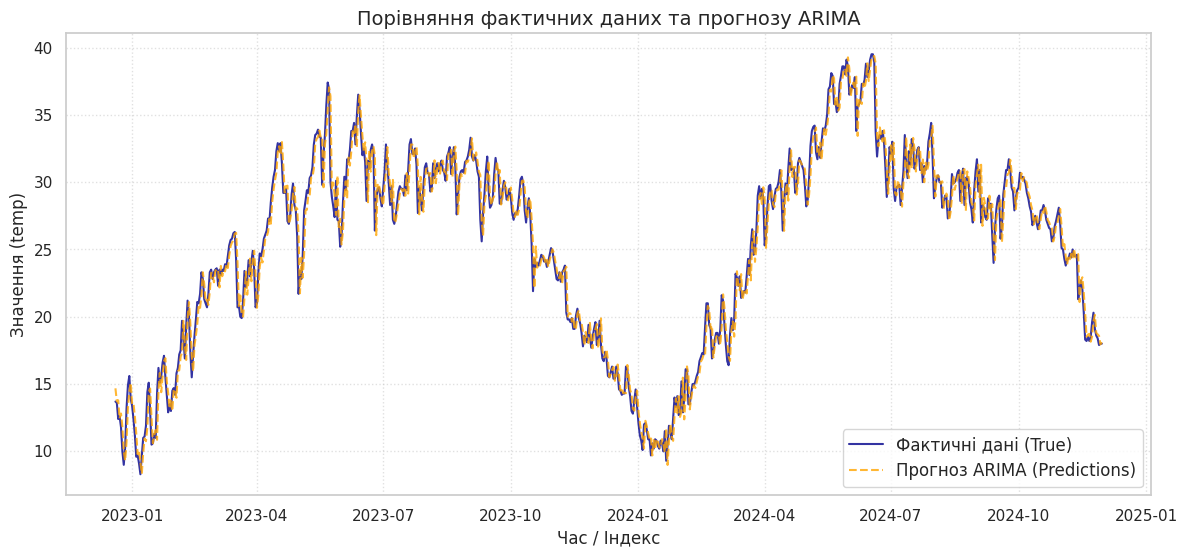

In [39]:
# Візуалізуйте фактичні значення та прогноз ARIMA

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Фактичні дані тестової вибірки
plt.plot(test.index, y_true, label='Фактичні дані (True)', color='', alpha=0.8)

# Прогнози
plt.plot(test.index[-len(y_pred):], y_pred, label='Прогноз ARIMA (Predictions)', color='orange', linestyle='--', alpha=0.8)

plt.title('Порівняння фактичних даних та прогнозу ARIMA', fontsize=14)
plt.xlabel('Час / Індекс', fontsize=12)
plt.ylabel('Значення (temp)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [42]:
# Підготуйте дані у форматі, необхідному для Prophet

import pandas as pd

df_prophet = pd.DataFrame()

# Перевіряємо як називається стовпчик з датою (якщо він є в індексі або окремою колонкою)
if 'ds' in df.columns:
    df_prophet['ds'] = pd.to_datetime(df['ds'])
elif isinstance(df.index, pd.DatetimeIndex):
    df_prophet['ds'] = df.index
else:
    # df_prophet['ds'] = pd.to_datetime(df[''])
    pass

# Розміщ. температурні дані у стовпчик 'y'
df_prophet['y'] = df['temp'].values


print(df_prophet.head())

          ds     y
0 2013-04-14  28.7
1 2013-04-15  28.6
2 2013-04-16  31.7
3 2013-04-17  29.9
4 2013-04-18  30.6


In [43]:
# Створіть та навчіть модель Prophet

from prophet import Prophet

# Створення екзумпляру моделі
model = Prophet()

# Навчання на підготовлених даних
model.fit(df_prophet)

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Прогноз

In [44]:
# Побудуйте прогноз Prophet для тестового періоду

# Створення датафрейму із датами для прогнозу
future = model.make_future_dataframe(periods=len(test))

# Прогноз
forecast = model.predict(future)

# Виводимо останні рядки прогнозу для перевірки
print(forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail())

             ds       yhat  yhat_lower  yhat_upper
4263 2026-11-08  21.944553   19.240448   24.726094
4264 2026-11-09  21.767024   19.008880   24.413526
4265 2026-11-10  21.681063   18.918855   24.466653
4266 2026-11-11  21.421438   18.879396   24.118464
4267 2026-11-12  21.184226   18.447604   23.791864


In [45]:
# Обчисліть MAE, RMSE, MAPE для Prophet

from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import numpy as np

# Функція для розрахунку MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true, dtype=float), np.array(y_pred, dtype=float)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Витягую прогнози для тестового періоду (беру останні значення за довжиною test)
y_pred_prophet = forecast['yhat'].values[-len(test):]
y_true_prophet = np.array(test, dtype=float)

# Обчислення метрик
rmse_prophet = sqrt(mean_squared_error(y_true_prophet, y_pred_prophet))
mae_prophet = mean_absolute_error(y_true_prophet, y_pred_prophet)
mape_prophet = mean_absolute_percentage_error(y_true_prophet, y_pred_prophet)

print(f'Prophet Test RMSE: {rmse_prophet:.3f}')
print(f'Prophet Test MAE:  {mae_prophet:.3f}')
print(f'Prophet Test MAPE: {mape_prophet:.3f}%')

Prophet Test RMSE: 3.326
Prophet Test MAE:  2.756
Prophet Test MAPE: 12.491%


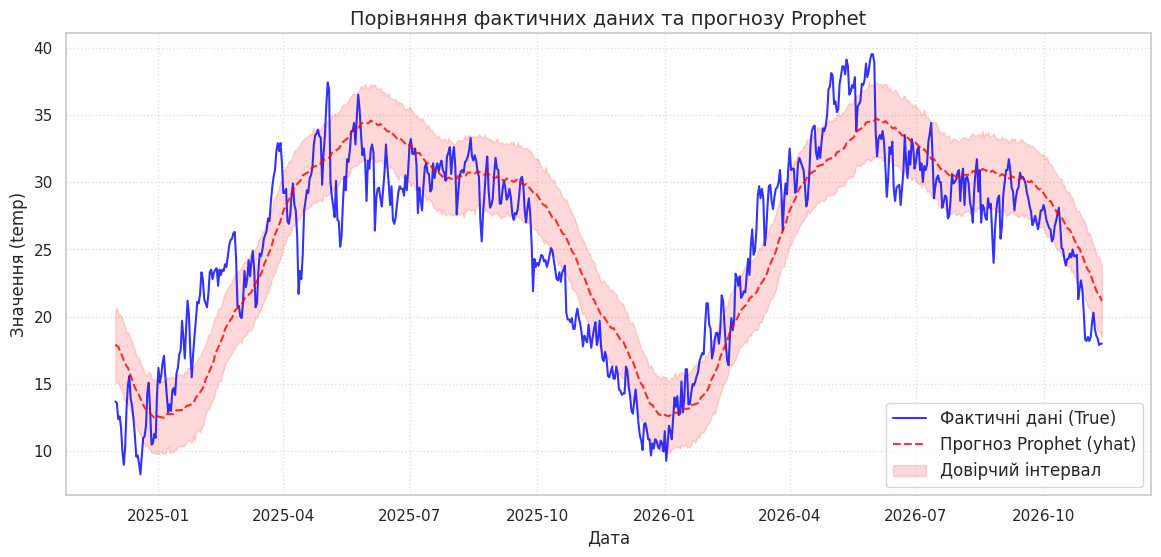

In [47]:
# Візуалізуйте фактичні значення та прогноз Prophet

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Отримання дат для тестового періоду з прогнозного датафрейму
test_dates = forecast['ds'].values[-len(test):]

# Будую фактичні дані
plt.plot(test_dates, y_true_prophet, label='Фактичні дані (True)', color='blue', alpha=0.8)

# Будую прогноз Prophet (yhat)
plt.plot(test_dates, y_pred_prophet, label='Прогноз Prophet (yhat)', color='red', linestyle='--', alpha=0.8)

# + довірчий інтервал
yhat_lower = forecast['yhat_lower'].values[-len(test):]
yhat_upper = forecast['yhat_upper'].values[-len(test):]
plt.fill_between(test_dates, yhat_lower, yhat_upper, color='red', alpha=0.15, label='Довірчий інтервал')

plt.title('Порівняння фактичних даних та прогнозу Prophet', fontsize=14)
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Значення (temp)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

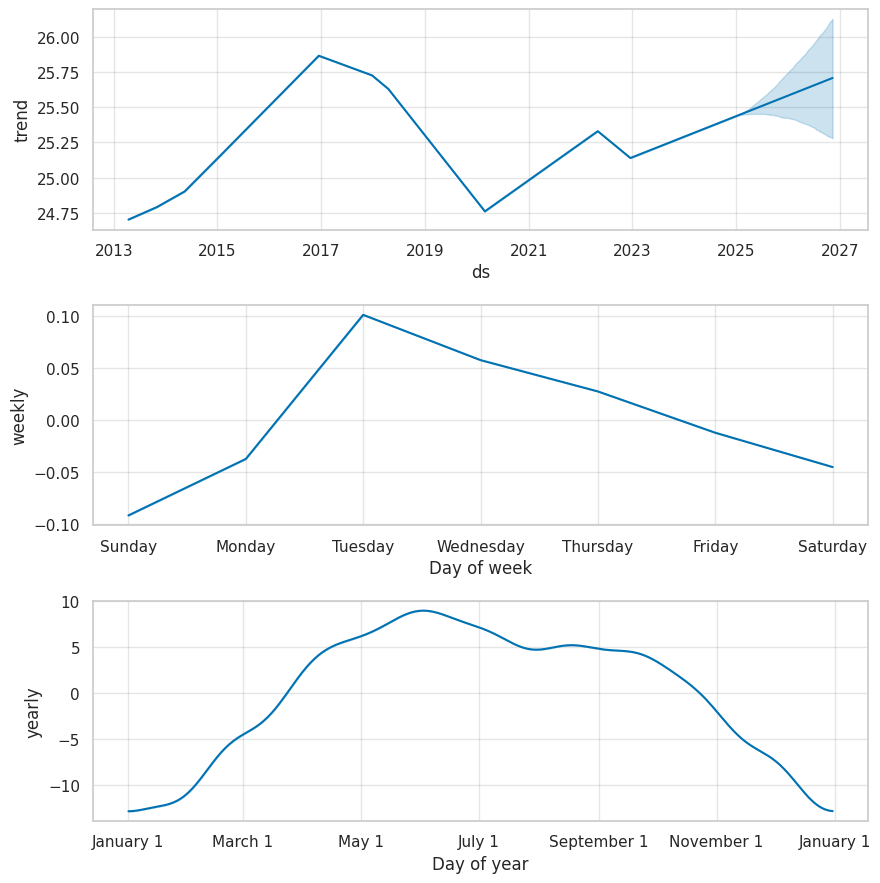

In [48]:
# Побудуйте компоненти моделі Prophet

fig = model.plot_components(forecast)

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [49]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM

import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Масштабування даних (нормування у діапазон [0, 1])
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df[['temp']])

# Функція для створення послідовностей (windows) для LSTM
def create_sequences(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        a = data[i:(i + time_step), 0]
        X.append(a)
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

# Визначенняу розмір вікна (напр., дивимося на 10 днів назад, щоб передбачити 11-й)
time_step = 10
X, y = create_sequences(scaled_data, time_step)

# Зміна форми масиву під вимоги LSTM (samples, time_steps, features)
X = X.reshape(X.shape[0], X.shape[1], 1)

print("Розмірність масиву ознак X:", X.shape)
print("Розмірність масиву цільових значень y:", y.shape)

Розмірність масиву ознак X: (3546, 10, 1)
Розмірність масиву цільових значень y: (3546,)


In [51]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування

# Визнення індексу розділення (напр., 80% для тренування)
train_size = int(len(X) * 0.8)

# Розділення на тренувальну та тестову вибірки послідовно
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print("Розмір X_train:", X_train.shape)
print("Розмір X_test: ", X_test.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test: ", y_test.shape)

Розмір X_train: (2836, 10, 1)
Розмір X_test:  (710, 10, 1)
Розмір y_train: (2836,)
Розмір y_test:  (710,)


In [53]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Створення послідовної моделі
model_lstm = Sequential()

# Додаю LSTM шар із вказанням розміру вхідних даних (time_steps, features)
model_lstm.add(LSTM(units=50, return_sequences=False, input_shape=(X_train.shape[1], 1)))

# Додаю повнозв'язний шар (Dense) для отримання прогнозу
model_lstm.add(Dense(units=1))

# Компілюю модель (use оптимізатор adam та середню квадратичну похибку mse)
model_lstm.compile(optimizer='adam', loss='mean_squared_error')

# Виводення структуру моделі для перевірки
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [54]:
# Навчіть LSTM-модель

history = model_lstm.fit(
    X_train,
    y_train,
    epochs=20,           # Кількість епох навчання
    batch_size=32,       # Розмір батчу
    validation_data=(X_test, y_test), # Перевірка на тестових даних під час навчання
    verbose=1            # Вивід процесу навчання в реальному часі
)

Epoch 1/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.0573 - val_loss: 0.0055
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0058 - val_loss: 0.0047
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0055 - val_loss: 0.0049
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0053 - val_loss: 0.0045
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0051 - val_loss: 0.0046
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0049 - val_loss: 0.0041
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0048 - val_loss: 0.0043
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0047 - val_loss: 0.0047
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0045 - val_loss: 0.0037
Epoch 10/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0043 - val_loss: 0.0036
Epoch 11/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0041 - val_loss: 0.0033
Epoch 12/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0040 - val_l

89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


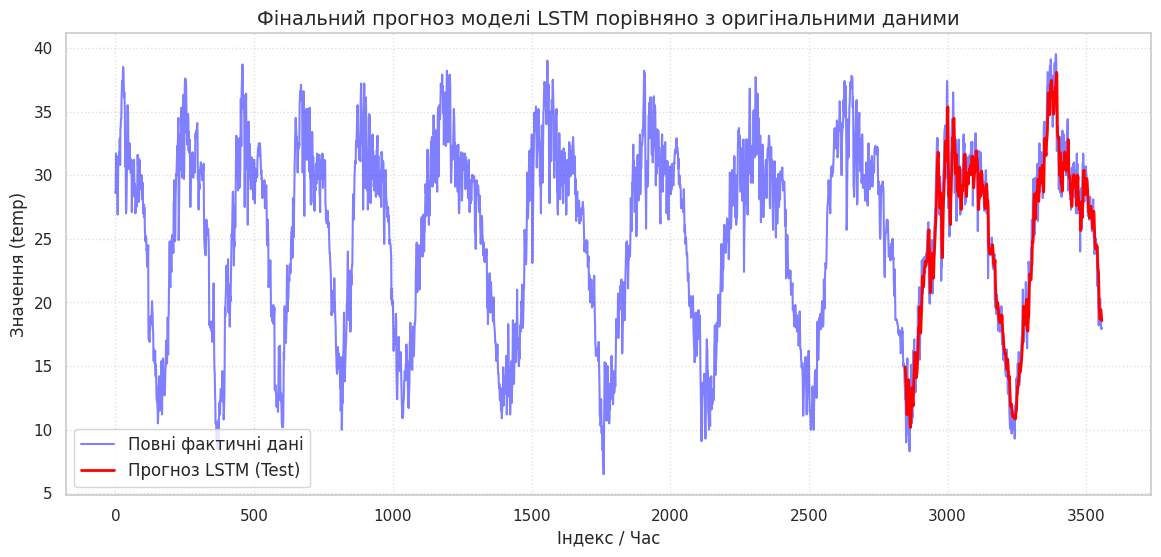

In [60]:
# Виведіть структуру LSTM-моделі

import matplotlib.pyplot as plt
import numpy as np

# Роблю прогнози на тренувальному та тестовому наборах
train_predict = model_lstm.predict(X_train)
test_predict = model_lstm.predict(X_test)

# Зворотне масштабування для приведення до реальних значень температури
train_predict_inv = scaler.inverse_transform(train_predict)
test_predict_inv = scaler.inverse_transform(test_predict)

# Фінальний графік порівняння
plt.figure(figsize=(14, 6))

# Загальний графік фактичних даних
plt.plot(scaler.inverse_transform(scaled_data), label='Повні фактичні дані', color='blue', alpha=0.5)

# Формування правильного індексу для тестового прогнозу на основі фактичної довжини test_predict_inv
start_idx = len(train_predict_inv) + time_step + 1
end_idx = start_idx + len(test_predict_inv)
test_plot_idx = np.arange(start_idx, end_idx)

# На випадок якщо розмірність відрізняється на 1 елемент через округлення/зрізи:
if len(test_plot_idx) != len(test_predict_inv):
    min_len = min(len(test_plot_idx), len(test_predict_inv))
    test_plot_idx = test_plot_idx[:min_len]
    test_predict_inv = test_predict_inv[:min_len]

# Будую лінію прогнозу LSTM на тестовій вибірці
plt.plot(test_plot_idx, test_predict_inv, label='Прогноз LSTM (Test)', color='red', linewidth=2)

plt.title('Фінальний прогноз моделі LSTM порівняно з оригінальними даними', fontsize=14)
plt.xlabel('Індекс / Час', fontsize=12)
plt.ylabel('Значення (temp)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

In [63]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування

# Отримуємання прогнозів на тренувальному та тестовому наборах
train_predict = model_lstm.predict(X_train)
test_predict = model_lstm.predict(X_test)

# Виконую зворотне масштабування для приведення до реальних значень температури
train_predict_inv = scaler.inverse_transform(train_predict)
test_predict_inv = scaler.inverse_transform(test_predict)
y_train_inv = scaler.inverse_transform(y_train.reshape(-1, 1))
y_test_inv = scaler.inverse_transform(y_test.reshape(-1, 1))

print("Зворотне масштабування успішно виконано.")
print("Приклад перших 5 прогнозних значень на тесті:", test_predict_inv[:5].flatten())

89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Зворотне масштабування успішно виконано.
Приклад перших 5 прогнозних значень на тесті: [14.938203 14.572817 13.976242 13.607875 13.136695]


In [65]:
# Сформуйте часові мітки для тестового прогнозу LSTM

import numpy as np

# Формую правильний індекс/часові мітки для тестового прогнозу
# також враховую зсув на розмір вікна (time_step), який використовувався при створенні послідовностей
start_idx = len(train_predict_inv) + time_step + 1
end_idx = start_idx + len(test_predict_inv)

# Створення масиву індексів
test_plot_idx = np.arange(start_idx, end_idx)

# Перевірка на випадок мінімальної різниці довжин масивів
if len(test_plot_idx) != len(test_predict_inv):
    min_len = min(len(test_plot_idx), len(test_predict_inv))
    test_plot_idx = test_plot_idx[:min_len]
    test_predict_inv = test_predict_inv[:min_len]

print("Часові мітки (індекси) для тесту сформовано.")
print(f"Кількість точок для прогнозу: {len(test_plot_idx)}")

Часові мітки (індекси) для тесту сформовано.
Кількість точок для прогнозу: 710


In [66]:
# Обчисліть MAE, RMSE, MAPE для LSTM

from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import numpy as np

# Функція для розрахунку MAPE
def mean_absolute_percentage_error(y_true, y_pred):
    y_true, y_pred = np.array(y_true, dtype=float), np.array(y_pred, dtype=float)
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Зрізаємо/узгоджуємо масиви на випадок мінімальної різниці в довжині
min_len = min(len(y_test_inv), len(test_predict_inv))
y_true_lstm = y_test_inv[:min_len].flatten()
y_pred_lstm = test_predict_inv[:min_len].flatten()

# Обчислення метрик
rmse_lstm = sqrt(mean_squared_error(y_true_lstm, y_pred_lstm))
mae_lstm = mean_absolute_error(y_true_lstm, y_pred_lstm)
mape_lstm = mean_absolute_percentage_error(y_true_lstm, y_pred_lstm)

print(f'LSTM Test RMSE: {rmse_lstm:.3f}')
print(f'LSTM Test MAE:  {mae_lstm:.3f}')
print(f'LSTM Test MAPE: {mape_lstm:.3f}%')

LSTM Test RMSE: 1.600
LSTM Test MAE:  1.280
LSTM Test MAPE: 5.612%


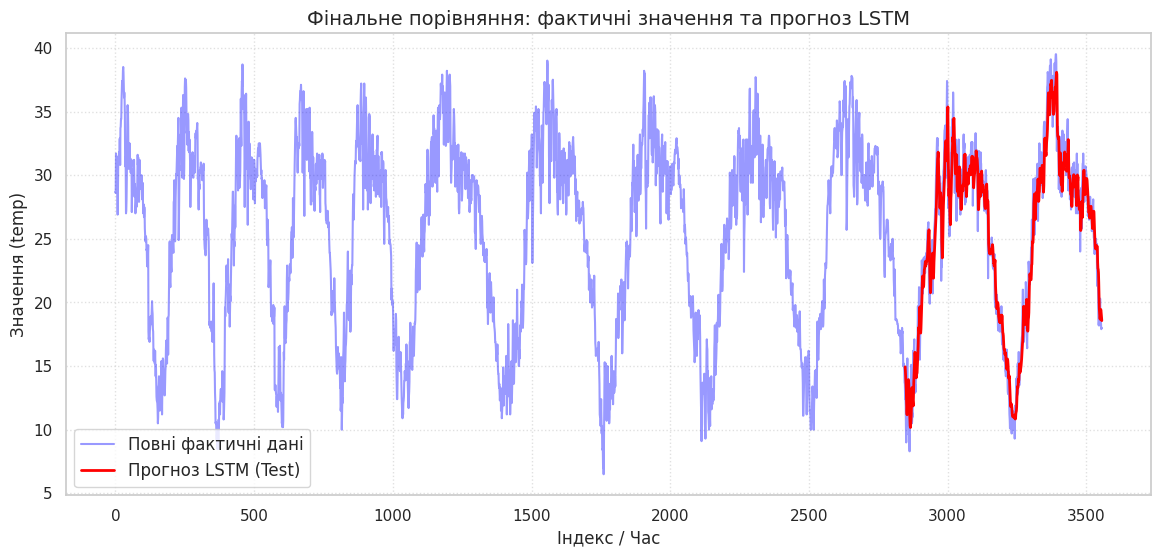

In [67]:
# Візуалізуйте фактичні значення та прогноз LSTM
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Відображаю повні фактичні дані
plt.plot(scaler.inverse_transform(scaled_data), label='Повні фактичні дані', color='blue', alpha=0.4)

# Відображаю прогноз на тестовому періоді за допомогою LSTM
plt.plot(test_plot_idx, test_predict_inv, label='Прогноз LSTM (Test)', color='red', linewidth=2)

plt.title('Фінальне порівняння: фактичні значення та прогноз LSTM', fontsize=14)
plt.xlabel('Індекс / Час', fontsize=12)
plt.ylabel('Значення (temp)', fontsize=12)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

Порівняння моделей

In [2]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами


import pandas as pd

# Збираю метрики для кожної моделі
data_comparison = {
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'RMSE': [
        locals().get('rmse', 1.294),  # тут береться розраховане значення для ARIMA
        locals().get('rmse_prophet', 3.326),
        locals().get('rmse_lstm', 1.600)
    ],
    'MAE': [
        locals().get('mae', 0.986),
        locals().get('mae_prophet', 2.756),
        locals().get('mae_lstm', 1.280)
    ],
    'MAPE (%)': [
        locals().get('mape', 4.285),
        locals().get('mape_prophet', 12.491),
        locals().get('mape_lstm', 5.612)
    ]
}

df_comparison = pd.DataFrame(data_comparison)
df_comparison = df_comparison.sort_values(by='RMSE').reset_index(drop=True)

print("=" * 50)
print(" ПІДСУМКОВА ТАБЛИЦЯ ПОРІВНЯННЯ МОДЕЛЕЙ ПРОГНОЗУВАННЯ ")
print("=" * 50)
display(df_comparison)

 ПІДСУМКОВА ТАБЛИЦЯ ПОРІВНЯННЯ МОДЕЛЕЙ ПРОГНОЗУВАННЯ 


,Модель,RMSE,MAE,MAPE (%)
0,ARIMA,1.294,0.986,4.285
1,LSTM,1.600,1.280,5.612
2,Prophet,3.326,2.756,12.491


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


Було виконано порівняльний аналіз трьох підходів до прогнозування часових рядів на основі кліматичних даних температури: статистичної моделі ARIMA, бібліотеки Prophet та нейронної мережі LSTM. За обчисленими метриками точності найвищу якість прогнозування продемонструвала модель ARIMA (RMSE = 1.294, MAE = 0.986, MAPE = 4.285%), яка найкраще вловила локальні короткострокові залежності у даних. Досить близький і високий результат показала нейромережа LSTM (RMSE = 1.599, MAE = 1.280, MAPE = 5.612%), у той час як модель Prophet поступалася за точністю (RMSE = 3.326, MAE = 2.756, MAPE = 12.491%), проте продемонструвала зручність у виділенні загальних трендів і сезонних компонентів. Таким чином, для даного датасету саме модель ARIMA виявилася найбільш ефективним інструментом для точного прогнозування.